**CSI 4106 Introduction to Artificial Intelligence**
*Assignment 1: Deep-Sea Mission Data Preparation*

# Identification

Name: *(reference solution for self-checking — use your own name)*
Student number: *(use your own)*
Report title: Preparing the ASRC deep-sea mission records for classification

This notebook is a practice key for comparing your own Assignment 1 results.
It is not a Brightspace submission. If you use it to revise work you hand in,
complete the AI Use Declaration yourself, as the handout requires.


# 1. Data and objective

The fictional **Abyssal Survey and Robotics Centre (ASRC)** operates
autonomous underwater vehicles for seabed mapping, environmental
monitoring, and deep-ocean surveys. Each row represents one mission. The
predictors are available before the main survey begins. The response,
`mission_interrupted`, is `1` when the vehicle returned before
completing its planned survey and `0` otherwise.

The data are fully synthetic and were created for teaching. The fleet in
this dataset is certified for planned survey depths no greater than
6,500 metres.

- [Assignment 1 data directory](https://github.com/turcotte/csi4106-f26/tree/main/assignments-data/a1)
- [asrc_missions_raw.csv](https://raw.githubusercontent.com/turcotte/csi4106-f26/main/assignments-data/a1/asrc_missions_raw.csv)


# 2. Data preparation and exploratory analysis

## 2.1 Load and audit the dataset

Load the supplied CSV data. The notebook must remain able to obtain the
source file from the supplied GitHub URL without a manual upload. Report
its shape, first five rows, initial data types, and number of distinct
values per column.


In [1]:
# Default pandas parsing is the initial audit. Blank fields and the token NA
# are already read as missing values [1]. The token "?" is not a default
# missing-value marker, so it is still visible in this first load.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = (
    "https://raw.githubusercontent.com/turcotte/csi4106-f26/main/"
    "assignments-data/a1/asrc_missions_raw.csv"
)

audited = pd.read_csv(DATA_URL)

print(f"Shape: {audited.shape[0]} rows x {audited.shape[1]} columns")
display(audited.head())

audit = pd.DataFrame(
    {
        "initial_dtype": audited.dtypes.astype(str),
        "n_distinct": audited.nunique(dropna=False),
        "n_missing_after_default_parse": audited.isna().sum(),
    }
)
display(audit)


Shape: 6371 rows x 17 columns


,mission_id,deployment_batch,telemetry_protocol,planned_depth_m,planned_depth_ft,descent_current_speed_m_s,water_temperature_c,sonar_noise_db,navigation_drift_m,battery_health_pct,thruster_vibration_mm_s,missions_since_service,vehicle_class,seabed_terrain,maintenance_grade,firmware_current,mission_interrupted
0,ASRC-M000001,ASRC-B0253,asrc_tlm_v4,1400.0,4593.2,0.55,3.3000000000000003,66.0,10.4,87.0,3.1,14,compact,ridge,good,1,0
1,ASRC-M000002,ASRC-B0648,asrc_tlm_v4,2700.0,8858.3,0.68,3.0,78.5,49.900000000000006,83.0,3.9,4,heavy_duty,vent_field,good,1,1
2,ASRC-M000003,ASRC-B0340,asrc_tlm_v4,2870.0,9416.0,0.15,3.6,78.7,5.800000000000001,92.0,5.2,10,survey,vent_field,fair,1,1
3,ASRC-M000004,ASRC-B0620,asrc_tlm_v4,2840.0,9317.6,0.39,2.5,77.30000000000001,54.6,89.0,3.9,9,survey,trench,good,1,0
4,ASRC-M000005,ASRC-B0332,asrc_tlm_v4,2430.0,7972.4,0.34,2.8000000000000003,77.80000000000001,8.700000000000001,89.0,3.4000000000000004,8,heavy_duty,vent_field,excellent,1,0


,initial_dtype,n_distinct,n_missing_after_default_parse
mission_id,str,6371,0
deployment_batch,str,850,0
telemetry_protocol,str,2,0
planned_depth_m,float64,582,0
planned_depth_ft,float64,576,0
descent_current_speed_m_s,float64,173,0
water_temperature_c,str,132,107
sonar_noise_db,str,340,84
navigation_drift_m,str,710,88
battery_health_pct,str,34,99


**Interpretation:**

The file has 6,371 missions and 17 columns. `mission_id` has 6,371 distinct
values, so each row is one mission. `deployment_batch` has 850 distinct
codes. `firmware_current` and `mission_interrupted` are already stored as
binary integers.

`planned_depth_m`, `planned_depth_ft`, and `descent_current_speed_m_s`
were inferred as floats. `water_temperature_c`, `sonar_noise_db`,
`navigation_drift_m`, `battery_health_pct`, `thruster_vibration_mm_s`,
and the text attributes stayed as strings. Those measurement columns
contain the non-numeric token `?`, which blocks numeric inference.
Default parsing has already turned empty fields and `NA` into missing
values, so the missing counts in the audit table are not yet the full
missing-data picture.


## 2.2 Handle missing values and data types

Investigate empty fields, `NA`, and `?`; convert them to `NaN`. Convert
numeric-like columns to numeric types, with parsing failures becoming
`NaN`. Report missing counts and percentages. Do not impute.


In [2]:
# A second read keeps every raw token so empty fields, NA, and ? can be counted
# before they are collapsed. Adapted from the pandas read_csv NA rules [1]
# and pandas.to_numeric [2].
raw = pd.read_csv(DATA_URL, dtype="string", keep_default_na=False)
SENTINELS = {"", "na", "n/a", "?"}


def as_clean_text(series: pd.Series) -> pd.Series:
    """Strip whitespace and map empty fields, NA, and ? to missing."""
    text = series.astype("string").str.strip()
    return text.mask(text.isna() | text.str.lower().isin(SENTINELS))


def sentinel_counts(series: pd.Series) -> pd.Series:
    text = series.astype("string")
    blank = text.str.strip().eq("")
    return pd.Series(
        {
            "blank": int(blank.sum()),
            "NA": int(text.str.upper().eq("NA").sum()),
            "?": int(text.eq("?").sum()),
        }
    )


text_columns = [
    "water_temperature_c",
    "sonar_noise_db",
    "navigation_drift_m",
    "battery_health_pct",
    "thruster_vibration_mm_s",
    "maintenance_grade",
    "vehicle_class",
    "seabed_terrain",
]
sentinel_table = pd.DataFrame({col: sentinel_counts(raw[col]) for col in text_columns}).T
sentinel_table = sentinel_table.loc[sentinel_table.sum(axis=1) > 0]
sentinel_table["total"] = sentinel_table.sum(axis=1)
display(sentinel_table)

NUMERIC_COLUMNS = [
    "planned_depth_m",
    "planned_depth_ft",
    "descent_current_speed_m_s",
    "water_temperature_c",
    "sonar_noise_db",
    "navigation_drift_m",
    "battery_health_pct",
    "thruster_vibration_mm_s",
    "missions_since_service",
    "firmware_current",
    "mission_interrupted",
]

work = pd.DataFrame(index=raw.index)
for column in raw.columns:
    cleaned = as_clean_text(raw[column])
    if column in NUMERIC_COLUMNS:
        work[column] = pd.to_numeric(cleaned, errors="coerce")
    else:
        work[column] = cleaned

for column in ("missions_since_service", "firmware_current", "mission_interrupted"):
    work[column] = work[column].astype("int64")

missing_counts = work.isna().sum()
missing_report = pd.DataFrame(
    {
        "n_missing": missing_counts,
        "pct_missing": (100 * missing_counts / len(work)).round(2),
    }
)
display(missing_report.loc[missing_report["n_missing"] > 0])
print("Dtypes after conversion:")
print(work.dtypes.astype(str).to_string())


,blank,NA,?,total
water_temperature_c,63,44,62,169
sonar_noise_db,51,33,39,123
navigation_drift_m,57,31,32,120
battery_health_pct,58,41,48,147
thruster_vibration_mm_s,50,37,39,126
maintenance_grade,55,39,35,129


,n_missing,pct_missing
water_temperature_c,169,2.65
sonar_noise_db,123,1.93
navigation_drift_m,120,1.88
battery_health_pct,147,2.31
thruster_vibration_mm_s,126,1.98
maintenance_grade,129,2.02


Dtypes after conversion:
mission_id                    string
deployment_batch              string
telemetry_protocol            string
planned_depth_m              Float64
planned_depth_ft             Float64
descent_current_speed_m_s    Float64
water_temperature_c          Float64
sonar_noise_db               Float64
navigation_drift_m           Float64
battery_health_pct           Float64
thruster_vibration_mm_s      Float64
missions_since_service         int64
vehicle_class                 string
seabed_terrain                string
maintenance_grade             string
firmware_current               int64
mission_interrupted            int64


**Findings and method:**

Every column was checked for empty fields, `NA`, and `?`. Only six columns
use those tokens. No other non-numeric tokens appeared, so `to_numeric`
did not create any extra missing values beyond those sentinels.

| Column | Blank | NA | ? | Missing | Percent |
| --- | ---: | ---: | ---: | ---: | ---: |
| water_temperature_c | 63 | 44 | 62 | 169 | 2.65% |
| sonar_noise_db | 51 | 33 | 39 | 123 | 1.93% |
| navigation_drift_m | 57 | 31 | 32 | 120 | 1.88% |
| battery_health_pct | 58 | 41 | 48 | 147 | 2.31% |
| thruster_vibration_mm_s | 50 | 37 | 39 | 126 | 1.98% |
| maintenance_grade | 55 | 39 | 35 | 129 | 2.02% |

The remaining columns have no missing values at this stage. Missing
measurements were left as `NaN`. Nothing was imputed.


## 2.3 Clean categorical attributes

Inspect every predictor represented by repeated text labels for
inconsistent category representations. Evaluate identifiers and
administrative codes in Task 2.6 rather than standardizing them merely
because they are text. Describe your investigation and cleaning method,
consolidate inconsistent labels where necessary, and show frequencies or
values before and after cleaning. Identify and state any meaningful
ordering among category levels.


In [3]:
LABEL_COLUMNS = ["vehicle_class", "seabed_terrain", "maintenance_grade"]


def canonicalize_label(series: pd.Series) -> pd.Series:
    """Case-fold labels and treat spaces and hyphens as the same separator."""
    labels = series.astype("string").str.lower()
    return labels.str.replace(r"[\s\-]+", "_", regex=True)


print("Identifiers and administrative codes were not relabelled here.")
for column in ("mission_id", "deployment_batch", "telemetry_protocol"):
    print(f"{column}: {work[column].nunique(dropna=False)} distinct values")
print("telemetry_protocol values:", work["telemetry_protocol"].value_counts().to_dict())

for column in LABEL_COLUMNS:
    before = work[column].value_counts(dropna=False)
    work[column] = canonicalize_label(work[column])
    after = work[column].value_counts(dropna=False)
    print(f"\n{column} — before")
    display(before.to_frame("count"))
    print(f"{column} — after")
    display(after.to_frame("count"))

GRADE_ORDER = ["poor", "fair", "good", "excellent"]
work["maintenance_grade"] = pd.Categorical(
    work["maintenance_grade"], categories=GRADE_ORDER, ordered=True
)
print("maintenance_grade order:", " < ".join(GRADE_ORDER))
print("vehicle_class and seabed_terrain have no meaningful order.")


Identifiers and administrative codes were not relabelled here.
mission_id: 6371 distinct values
deployment_batch: 850 distinct values
telemetry_protocol: 2 distinct values
telemetry_protocol values: {'asrc_tlm_v4': 6318, 'asrc_tlm_v3': 53}

vehicle_class — before


,count
vehicle_class,
survey,3140
compact,1858
heavy_duty,1292
SURVEY,31
Survey,18
Compact,13
Heavy Duty,11
heavy-duty,8


vehicle_class — after


,count
vehicle_class,
survey,3189
compact,1871
heavy_duty,1311



seabed_terrain — before


...


maintenance_grade — before


,count
maintenance_grade,
good,2498
excellent,2090
fair,1159
poor,417
<NA>,129
Good,24
EXCELLENT,23
Excellent,18
Poor,6


maintenance_grade — after


,count
maintenance_grade,
good,2522
excellent,2131
fair,1166
poor,423
<NA>,129


maintenance_grade order: poor < fair < good < excellent
vehicle_class and seabed_terrain have no meaningful order.


**Findings and method:**

`mission_id`, `deployment_batch`, and `telemetry_protocol` are an
identifier and two administrative codes. Their labels are already
internally consistent (`asrc_tlm_v3` and `asrc_tlm_v4` for the protocol).
They are left unchanged here and judged in Section 2.6.

The repeated-label predictors were `vehicle_class`, `seabed_terrain`, and
`maintenance_grade`. The same level was written with different
capitalization, a leading space, or a space or hyphen instead of an
underscore. Cleaning stripped whitespace, case-folded the text, and
replaced spaces and hyphens with `_`.

After cleaning, the levels are:

- `vehicle_class`: `compact` (1,871), `heavy_duty` (1,311), `survey` (3,189). Nominal.
- `seabed_terrain`: `plain` (2,347), `ridge` (1,794), `trench` (1,245), `vent_field` (985). Nominal.
- `maintenance_grade`: `poor` (423) < `fair` (1,166) < `good` (2,522) < `excellent` (2,131), plus 129 missing. This is the only ordered attribute. The order is the inspection scale from worst to best, and the cleaned labels keep that meaning.


## 2.4 Apply validity rules

Use the variable meanings, units, and ASRC operating context to define
and justify validation rules. Report the affected attributes and counts,
replace invalid measurements with `NaN`, and retain unusual but possible
observations. Do not guess corrections, reconstruct values from another
column, or remove entire missions.


In [4]:
# International foot: 1 ft = 0.3048 m exactly, so 1 m = 3.280839895... ft [5].
# The file uses the five-decimal factor below; Section 2.6 shows that it
# matches the stored foot values after rounding to 0.1 ft.
METRES_TO_FEET = 3.28084
MAX_CERTIFIED_DEPTH_M = 6500

depth_m_before_rules = work["planned_depth_m"].copy()
rules = [
    (
        "planned_depth_m",
        (work["planned_depth_m"] <= 0) | (work["planned_depth_m"] > MAX_CERTIFIED_DEPTH_M),
        "A planned depth must be positive and no deeper than the 6,500 m fleet limit.",
    ),
    (
        "planned_depth_ft",
        (work["planned_depth_ft"] <= 0)
        | (work["planned_depth_ft"] > MAX_CERTIFIED_DEPTH_M * METRES_TO_FEET),
        "The same 6,500 m limit, expressed in feet.",
    ),
    (
        "descent_current_speed_m_s",
        work["descent_current_speed_m_s"] < 0,
        "Current speed is a magnitude, so a negative value cannot be valid.",
    ),
    (
        "water_temperature_c",
        (work["water_temperature_c"] < -2) | (work["water_temperature_c"] > 40),
        "Seawater is liquid down to about -2 C and does not reach 40 C as an ambient descent mean.",
    ),
    (
        "navigation_drift_m",
        work["navigation_drift_m"] < 0,
        "The position difference is stored as a distance, so it cannot be negative.",
    ),
    (
        "battery_health_pct",
        (work["battery_health_pct"] < 0) | (work["battery_health_pct"] > 100),
        "State of health is a percentage and cannot fall outside 0 to 100.",
    ),
    (
        "thruster_vibration_mm_s",
        work["thruster_vibration_mm_s"] < 0,
        "RMS vibration is a magnitude and cannot be negative.",
    ),
    (
        "missions_since_service",
        work["missions_since_service"] < 0,
        "A mission count cannot be negative.",
    ),
]

rule_rows = []
for column, invalid, reason in rules:
    invalid = invalid.fillna(False)
    rule_rows.append(
        {
            "attribute": column,
            "n_invalid": int(invalid.sum()),
            "rule": reason,
        }
    )
    work.loc[invalid, column] = np.nan

rule_report = pd.DataFrame(rule_rows)
display(rule_report)

print("Invalid planned_depth_m values:")
display(depth_m_before_rules.loc[depth_m_before_rules > MAX_CERTIFIED_DEPTH_M].to_frame("planned_depth_m"))
print("Invalid current speeds:")
print(
    work.loc[work["descent_current_speed_m_s"].isna() & depth_m_before_rules.notna(), "descent_current_speed_m_s"]
    .pipe(lambda s: raw.loc[s.index, "descent_current_speed_m_s"].value_counts())
    .to_string()
)
print("\nInvalid battery health values:")
print(raw.loc[pd.to_numeric(as_clean_text(raw["battery_health_pct"]), errors="coerce") > 100, "battery_health_pct"].value_counts().to_string())

extremes = pd.DataFrame(
    {
        "min_retained": work[
            [
                "planned_depth_m",
                "descent_current_speed_m_s",
                "water_temperature_c",
                "sonar_noise_db",
                "navigation_drift_m",
                "battery_health_pct",
                "thruster_vibration_mm_s",
                "missions_since_service",
            ]
        ].min(),
        "max_retained": work[
            [
                "planned_depth_m",
                "descent_current_speed_m_s",
                "water_temperature_c",
                "sonar_noise_db",
                "navigation_drift_m",
                "battery_health_pct",
                "thruster_vibration_mm_s",
                "missions_since_service",
            ]
        ].max(),
    }
)
display(extremes)


,attribute,n_invalid,rule
0,planned_depth_m,6,A planned depth must be positive and no deeper...
1,planned_depth_ft,0,"The same 6,500 m limit, expressed in feet."
2,descent_current_speed_m_s,6,"Current speed is a magnitude, so a negative va..."
3,water_temperature_c,0,Seawater is liquid down to about -2 C and does...
4,navigation_drift_m,0,The position difference is stored as a distanc...
5,battery_health_pct,6,State of health is a percentage and cannot fal...
6,thruster_vibration_mm_s,0,RMS vibration is a magnitude and cannot be neg...
7,missions_since_service,0,A mission count cannot be negative.


Invalid planned_depth_m values:


,planned_depth_m
499,28700.0
1443,23200.0
3173,33100.0
5192,12300.0
5247,19700.0
5395,37800.0


Invalid current speeds:
descent_current_speed_m_s
-0.43    1
-1.21    1
-0.15    1
-0.84    1
-0.06    1
-0.41    1

Invalid battery health values:
battery_health_pct
108.0    6


,min_retained,max_retained
planned_depth_m,280.0,6290.0
descent_current_speed_m_s,0.02,2.06
water_temperature_c,-1.5,13.3
sonar_noise_db,54.6,95.0
navigation_drift_m,0.8,132.2
battery_health_pct,67.0,99.0
thruster_vibration_mm_s,0.2,45.0
missions_since_service,0.0,55.0


**Findings and justification:**

Three attributes contained values that cannot be valid measurements.
Those cells were set to missing. The missions themselves were kept.

- `planned_depth_m`: 6 values, from 12,300 m to 37,800 m. The fleet is certified only to 6,500 m, and every one of these values is also deeper than the ocean. They were not divided by 10, even though the foot column shows that a tenfold recording error would explain them. Reconstructing a depth from another column is outside the task.
- `descent_current_speed_m_s`: 6 negative values (−1.21, −0.84, −0.43, −0.41, −0.15, −0.06). Speed is not a signed velocity in this field.
- `battery_health_pct`: 6 values of 108. A percentage state of health cannot exceed 100. The low value 67% was kept.

Rules with no invalid rows were still applied: non-positive depth in feet, water temperature below −2 °C or above 40 °C, and negative drift, vibration, or mission counts. `sonar_noise_db` was not forced into a hard range. Decibels can sit below the reference level, and the observed span, 54.6 dB to 95.0 dB, is a plausible calibration range.

Retained extremes, and why they are possible:

- Planned depth of 6,290 m is inside the 6,500 m limit. The matching maximum in feet is 20,636.5 ft.
- A descent current of 2.06 m/s is fast for the deep ocean and still a possible speed.
- Water temperature from −1.5 °C to 13.3 °C is inside the liquid-seawater range. Seawater can be colder than 0 °C.
- Navigation drift of 132.2 m is large and still a possible position difference.
- Thruster vibration of 45 mm/s is a rough self-test result and still a possible RMS reading.
- Zero missions since service means the vehicle was just serviced. A count of 55 is high and still possible.


## 2.5 Explore distributions and relationships

Before removing any attributes, create a compact summary table and
labelled histogram grid for the quantitative measurement and count
attributes. Exclude identifiers, administrative codes, categorical
labels, binary indicators, and the response, even if they are stored
numerically. At minimum, report the non-missing count, mean, standard
deviation, quartiles, minimum, maximum, and skewness.


,non_missing,mean,std_dev,min,25%,median,75%,max,skewness
planned_depth_m,6365.0,1999.929301,1402.264828,280.0,770.0,1640.0,2870.0,6290.0,0.925
planned_depth_ft,6371.0,6563.240057,4599.603801,918.6,2559.1,5380.6,9416.0,20636.5,0.924
descent_current_speed_m_s,6365.0,0.423049,0.287011,0.02,0.21,0.36,0.56,2.06,1.251
water_temperature_c,6202.0,4.06048,2.268177,-1.5,2.4,3.6,5.7,13.3,0.535
sonar_noise_db,6248.0,72.019062,6.820898,54.6,66.7,72.2,77.1,95.0,0.049
navigation_drift_m,6251.0,21.752936,15.810234,0.8,9.8,18.0,29.3,132.2,1.483
battery_health_pct,6218.0,87.952396,4.271393,67.0,85.0,88.0,91.0,99.0,-0.239
thruster_vibration_mm_s,6245.0,4.651305,3.138782,0.2,2.5,3.9,6.0,45.0,2.187
missions_since_service,6371.0,12.605713,7.864687,0.0,7.0,11.0,17.0,55.0,1.108


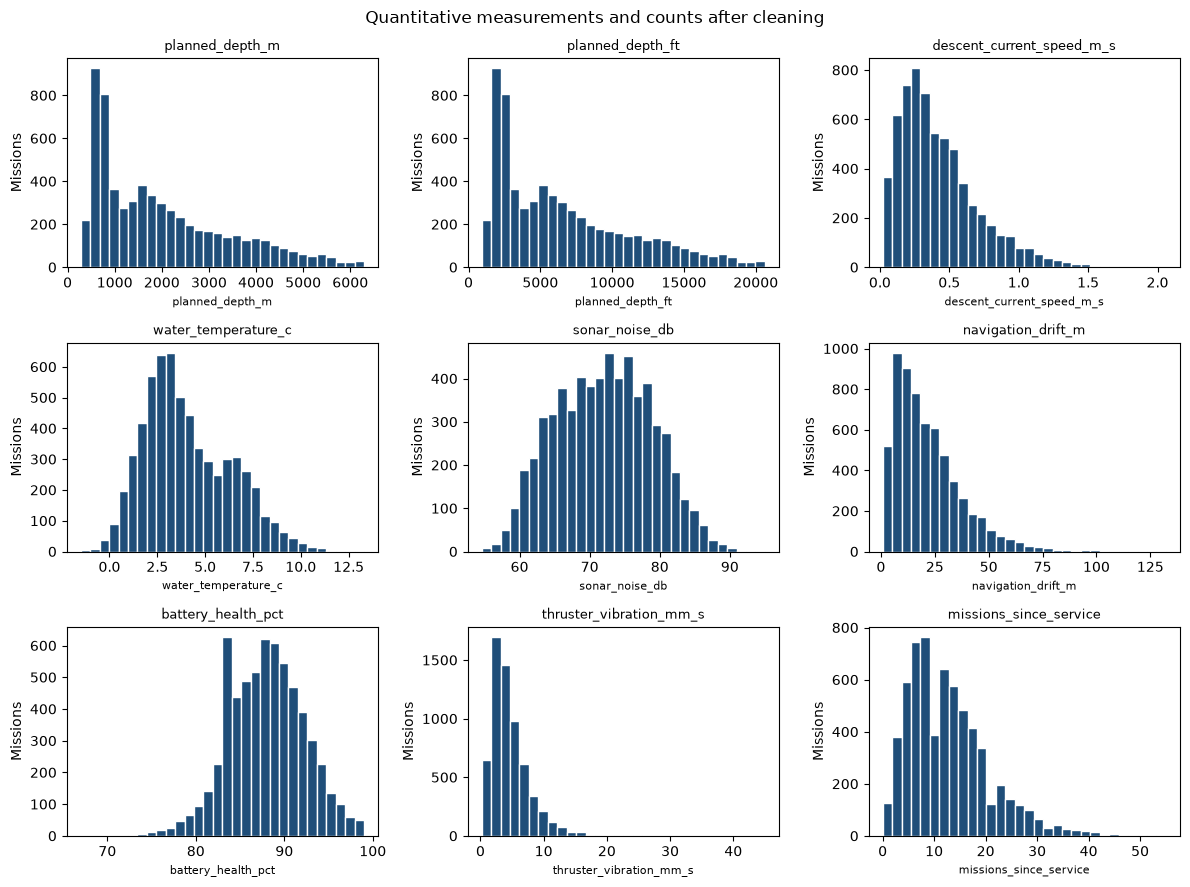

In [5]:
QUANTITATIVE = [
    "planned_depth_m",
    "planned_depth_ft",
    "descent_current_speed_m_s",
    "water_temperature_c",
    "sonar_noise_db",
    "navigation_drift_m",
    "battery_health_pct",
    "thruster_vibration_mm_s",
    "missions_since_service",
]

summary = work[QUANTITATIVE].describe().T
summary = summary.rename(columns={"count": "non_missing", "std": "std_dev", "50%": "median"})
summary["skewness"] = work[QUANTITATIVE].skew()
summary = summary[
    ["non_missing", "mean", "std_dev", "min", "25%", "median", "75%", "max", "skewness"]
]
display(summary.round(3))

n_cols = 3
n_rows = int(np.ceil(len(QUANTITATIVE) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 9))
for axis, column in zip(axes.ravel(), QUANTITATIVE):
    axis.hist(work[column].dropna(), bins=30, color="#1f4e79", edgecolor="white")
    axis.set_title(column, fontsize=9)
    axis.set_xlabel(column, fontsize=8)
    axis.set_ylabel("Missions")
for axis in axes.ravel()[len(QUANTITATIVE) :]:
    axis.axis("off")
fig.suptitle("Quantitative measurements and counts after cleaning")
fig.tight_layout()
plt.show()


Choose three attributes with different shapes. Discuss centre, spread,
symmetry or skewness, modality, and valid extreme observations.

**Detailed distribution analysis:**

Three different shapes:

1. `sonar_noise_db` is approximately symmetric and unimodal. The mean is 72.0 dB and the median is 72.2 dB, with a standard deviation of 6.8 dB and skewness near 0.05. The histogram rises and falls in one peak. The tails, 54.6 dB and 95.0 dB, are the ends of that peak rather than a second mode or a data error.
2. `planned_depth_m` is unimodal and right-skewed (skewness about 0.93). The mean, about 2,000 m, sits above the median, 1,640 m. Most plans are shallower than 2,000 m, and a long tail of deeper plans reaches the retained maximum of 6,290 m. `planned_depth_ft` has the same shape, which is the first visual hint that the two depth columns carry the same information.
3. `thruster_vibration_mm_s` is strongly right-skewed (skewness about 2.19) and unimodal, with a long right tail. The median is 3.9 mm/s and the mean is 4.7 mm/s. The retained maximum, 45 mm/s, is a rare rough reading, not a second mode and not an impossible value.

`water_temperature_c` is also mildly right-skewed (skewness about 0.53), centred near 3.6 °C. `battery_health_pct` is the only mildly left-skewed measurement, piled up near 88% with a tail down to 67%.


Create a Pearson correlation heat map for the quantitative attributes.
Do not add identifiers, administrative codes, categorical encodings,
binary indicators, or the response unless specifically justified.
Discuss the strongest duplicate and non-duplicate relationships and
whether they are plausible. Add one joint plot involving at least two
attributes, and explain what it reveals beyond the univariate
histograms.


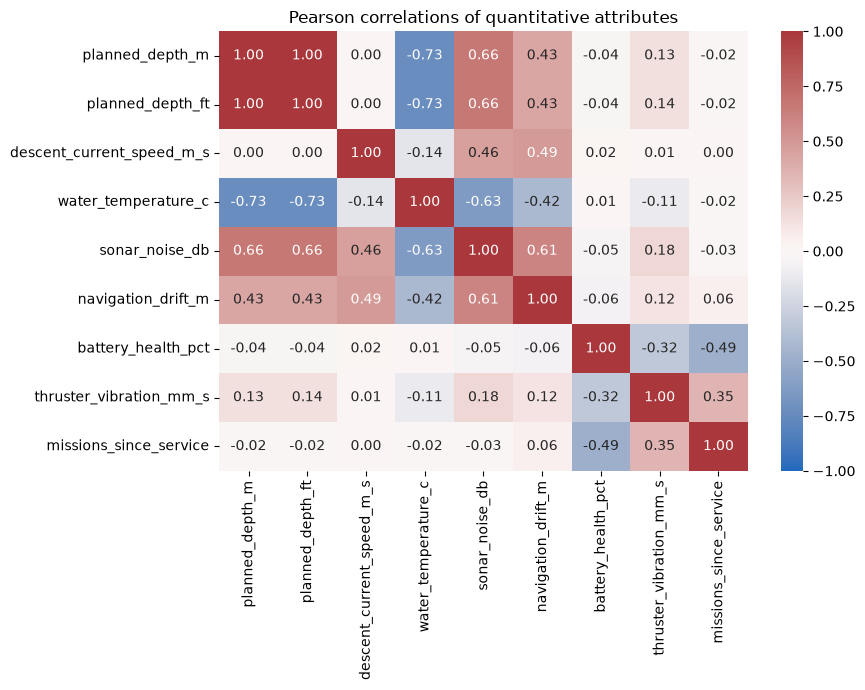

Strongest pairs:
+1.000  planned_depth_m  with  planned_depth_ft
-0.729  planned_depth_ft  with  water_temperature_c
-0.729  planned_depth_m  with  water_temperature_c
+0.665  planned_depth_m  with  sonar_noise_db
+0.665  planned_depth_ft  with  sonar_noise_db
-0.630  water_temperature_c  with  sonar_noise_db
+0.609  sonar_noise_db  with  navigation_drift_m
+0.492  descent_current_speed_m_s  with  navigation_drift_m


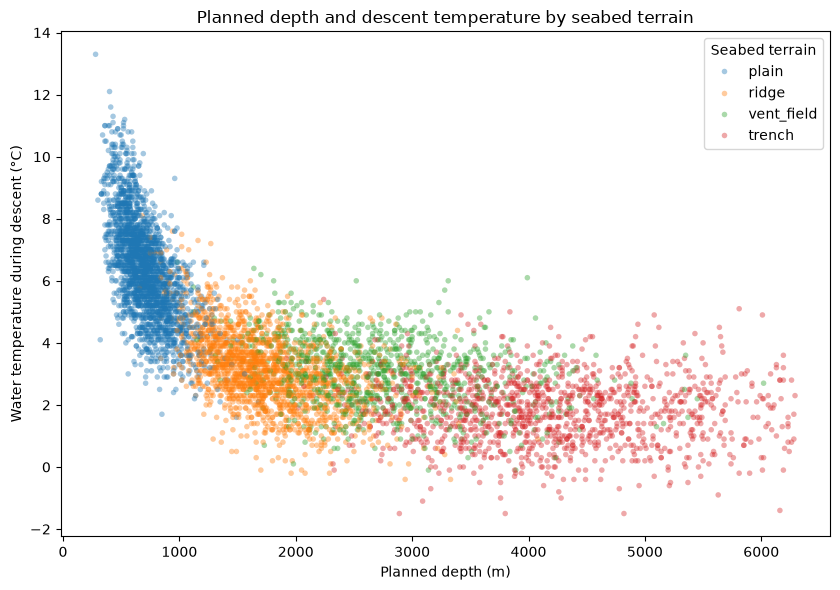

,planned_depth_m,water_temperature_c
seabed_terrain,,
plain,713.0,6.4
ridge,1752.0,3.1
trench,4187.3,1.8
vent_field,2759.0,3.1


In [6]:
# Pearson correlations among quantitative measurements only [3], [4].
correlation = work[QUANTITATIVE].corr(method="pearson")
fig, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axis,
)
axis.set_title("Pearson correlations of quantitative attributes")
fig.tight_layout()
plt.show()

pairs = []
for i, left in enumerate(QUANTITATIVE):
    for right in QUANTITATIVE[i + 1 :]:
        pairs.append((correlation.loc[left, right], left, right))
pairs = sorted(pairs, key=lambda item: abs(item[0]), reverse=True)
print("Strongest pairs:")
for value, left, right in pairs[:8]:
    print(f"{value:+.3f}  {left}  with  {right}")

fig, axis = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(
    data=work,
    x="planned_depth_m",
    y="water_temperature_c",
    hue="seabed_terrain",
    hue_order=["plain", "ridge", "vent_field", "trench"],
    alpha=0.4,
    s=16,
    edgecolor="none",
    ax=axis,
)
axis.set_title("Planned depth and descent temperature by seabed terrain")
axis.set_xlabel("Planned depth (m)")
axis.set_ylabel("Water temperature during descent (°C)")
axis.legend(title="Seabed terrain")
fig.tight_layout()
plt.show()

terrain_means = (
    work.groupby("seabed_terrain", observed=True)[["planned_depth_m", "water_temperature_c"]]
    .mean()
    .round(1)
)
display(terrain_means)


**Relationship analysis:**

The heat map uses only the nine quantitative measurements and counts.
Identifiers, batch and protocol codes, category labels, `firmware_current`,
and `mission_interrupted` are excluded. Binary indicators and the response
would change the meaning of the map, and there is no reason to add them
at this stage.

The duplicate relationship is `planned_depth_m` with `planned_depth_ft`.
After the six impossible metre values are missing, the Pearson correlation
is 1.00. That is expected if one column is the other column in another
unit. Section 2.6 confirms the conversion directly. Before those six
values were removed, the same correlation was only about 0.88, because
the tenfold metre errors pulled the coefficient down. Correlation by
itself would have understated the duplication.

The strongest relationship that is not a duplicate is `planned_depth_m`
with `water_temperature_c` (r ≈ −0.73). Deeper plans coincide with colder
water sampled on the way down. That is plausible, and the two columns
measure different things: a mission setting and an environmental
condition. Other plausible, non-duplicate links are planned depth with
sonar noise (r ≈ 0.66), sonar noise with water temperature (r ≈ −0.63),
sonar noise with navigation drift (r ≈ 0.61), and battery health with
missions since service (r ≈ −0.49). Battery health falling as missions
accumulate is wear, not a second copy of the same measurement.

The joint plot shows structure the separate histograms cannot. Colouring
depth against temperature by seabed terrain separates four operating
regions: plains are shallow and warmer (about 710 m and 6.4 °C), ridges
are intermediate, vent fields sit deeper but at a similar temperature to
ridges (about 2,760 m and 3.1 °C), and trenches are the deepest and
coldest (about 4,190 m and 1.8 °C). The right skew of depth is partly a
mixture of these terrain bands, not a single smooth pile of missions.


## 2.6 Select attributes for the analysis-ready dataset

Using the preceding exploration and the meaning of each attribute,
investigate unique identifiers, high-cardinality administrative fields,
quasi-constant attributes (one value in at least 99% of observations),
and deterministic or near-deterministic duplicate measurements. List and
justify every removed attribute. Demonstrate a suspected deterministic
or alternate-unit duplicate with a direct numerical relationship, such
as a conversion error or residual; correlation alone is insufficient
evidence of duplication. Do not remove strongly correlated attributes
when they measure different concepts.


In [7]:
screening = []
for column in work.columns:
    counts = work[column].value_counts(dropna=False)
    top_value = counts.index[0]
    top_count = int(counts.iloc[0])
    screening.append(
        {
            "attribute": column,
            "n_distinct": int(work[column].nunique(dropna=False)),
            "top_value": str(top_value),
            "top_count": top_count,
            "top_share": top_count / len(work),
        }
    )
screening = pd.DataFrame(screening).set_index("attribute")
display(screening.sort_values("top_share", ascending=False).round(4))

comparable = work["planned_depth_m"].notna() & work["planned_depth_ft"].notna()
predicted_ft = (work.loc[comparable, "planned_depth_m"] * METRES_TO_FEET).round(1)
residual_ft = work.loc[comparable, "planned_depth_ft"] - predicted_ft
print(f"Rows with both depth units: {int(comparable.sum())}")
print(f"Maximum absolute residual, feet minus round(metres x 3.28084, 1): {residual_ft.abs().max():.4f}")
print(f"Share of those rows with residual 0: {(residual_ft == 0).mean():.6f}")

tenfold = depth_m_before_rules > MAX_CERTIFIED_DEPTH_M
tenfold_check = pd.DataFrame(
    {
        "planned_depth_m": depth_m_before_rules.loc[tenfold],
        "metres_divided_by_10": depth_m_before_rules.loc[tenfold] / 10,
        "planned_depth_ft": work.loc[tenfold, "planned_depth_ft"],
    }
)
tenfold_check["feet_from_corrected_metres"] = (
    tenfold_check["metres_divided_by_10"] * METRES_TO_FEET
).round(1)
display(tenfold_check)

REMOVED = [
    "mission_id",
    "deployment_batch",
    "telemetry_protocol",
    "planned_depth_ft",
]
predictors = [
    column
    for column in work.columns
    if column not in REMOVED and column != "mission_interrupted"
]
analysis_columns = predictors + ["mission_interrupted"]
print("Retained columns, response last:")
print(analysis_columns)


,n_distinct,top_value,top_count,top_share
attribute,,,,
telemetry_protocol,2,asrc_tlm_v4,6318,0.9917
firmware_current,2,1,5157,0.8094
mission_interrupted,2,0,4295,0.6741
vehicle_class,3,survey,3189,0.5005
maintenance_grade,5,good,2522,0.3959
seabed_terrain,4,plain,2347,0.3684
battery_health_pct,32,88.0,620,0.0973
missions_since_service,53,8.0,395,0.0620
water_temperature_c,130,<NA>,169,0.0265


Rows with both depth units: 6365
Maximum absolute residual, feet minus round(metres x 3.28084, 1): 0.0000
Share of those rows with residual 0: 1.000000


,planned_depth_m,metres_divided_by_10,planned_depth_ft,feet_from_corrected_metres
499,28700.0,2870.0,9416.0,9416.0
1443,23200.0,2320.0,7611.5,7611.5
3173,33100.0,3310.0,10859.6,10859.6
5192,12300.0,1230.0,4035.4,4035.4
5247,19700.0,1970.0,6463.3,6463.3
5395,37800.0,3780.0,12401.6,12401.6


Retained columns, response last:
['planned_depth_m', 'descent_current_speed_m_s', 'water_temperature_c', 'sonar_noise_db', 'navigation_drift_m', 'battery_health_pct', 'thruster_vibration_mm_s', 'missions_since_service', 'vehicle_class', 'seabed_terrain', 'maintenance_grade', 'firmware_current', 'mission_interrupted']


**Removed attributes and evidence:**

| Attribute | Decision | Evidence |
| --- | --- | --- |
| `mission_id` | Remove. Unique identifier. | 6,371 distinct values in 6,371 rows. It names the mission and does not describe it. |
| `deployment_batch` | Remove. High-cardinality administrative code. | 850 batch codes. The most common code appears 8 times (0.13% of missions). The field records how the row entered the data system, not the vehicle or the environment. |
| `telemetry_protocol` | Remove. Quasi-constant administrative code. | `asrc_tlm_v4` accounts for 6,318 of 6,371 rows, which is 99.17%. The cutoff in the handout is 99%. The other code, `asrc_tlm_v3`, appears on 53 missions. |
| `planned_depth_ft` | Remove. Alternate-unit duplicate of `planned_depth_m`. | On all 6,365 rows with a valid metre depth, `planned_depth_ft` equals `round(planned_depth_m × 3.28084, 1)` exactly, so the residual is 0. The factor 3.28084 is `1 / 0.3048` rounded to five decimals. The international foot is exactly 0.3048 m [5]. Metres are kept because the certification limit and the other measurements are metric. |

The six rejected metre values are a tenfold recording error: `planned_depth_ft` equals `round((planned_depth_m / 10) × 3.28084, 1)` on those rows. That check is evidence about the error. It is not used to fill the missing metre depths back in.

These correlated attributes stay, because they measure different concepts:

- `planned_depth_m` and `water_temperature_c` (r ≈ −0.73)
- `planned_depth_m` and `sonar_noise_db` (r ≈ 0.66)
- `battery_health_pct` and `missions_since_service` (r ≈ −0.49)
- `thruster_vibration_mm_s` and `missions_since_service` (r ≈ 0.35)

`firmware_current` stays. It is binary, so it was left out of the histograms, but the value 1 accounts for 5,157 / 6,371 = 80.94% of missions, which is below the 99% quasi-constant cutoff.


## 2.7 Examine the response

Report counts and proportions for `mission_interrupted`, include a
labelled bar chart, and briefly characterize the class balance. Do not
train a model.


,count,proportion,label
mission_interrupted,,,
0,4295,0.6741,completed survey
1,2076,0.3259,returned before completion


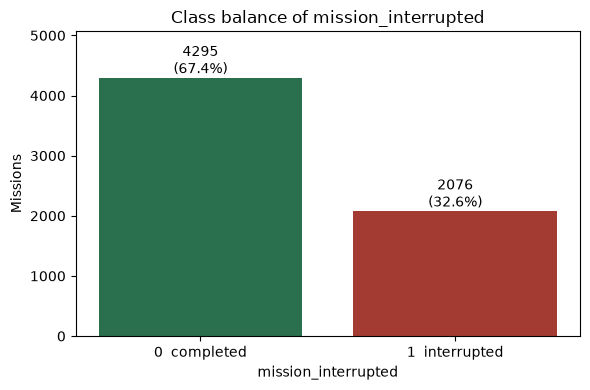

No classifier was trained.


In [8]:
response_counts = work["mission_interrupted"].value_counts().sort_index()
response_share = response_counts / response_counts.sum()
response_table = pd.DataFrame(
    {
        "count": response_counts,
        "proportion": response_share.round(4),
        "label": ["completed survey", "returned before completion"],
    }
)
display(response_table)

fig, axis = plt.subplots(figsize=(6, 4))
bar_labels = ["0  completed", "1  interrupted"]
bars = axis.bar(bar_labels, response_counts.to_numpy(), color=["#2a6f4e", "#a33b32"])
axis.set_ylabel("Missions")
axis.set_xlabel("mission_interrupted")
axis.set_title("Class balance of mission_interrupted")
for bar, count, share in zip(bars, response_counts.to_numpy(), response_share.to_numpy()):
    axis.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({share:.1%})",
        ha="center",
        va="bottom",
    )
axis.set_ylim(0, response_counts.max() * 1.18)
fig.tight_layout()
plt.show()
print("No classifier was trained.")


**Interpretation:**

Of 6,371 missions, 4,295 (67.41%) have `mission_interrupted` = 0 and
2,076 (32.59%) have `mission_interrupted` = 1. Completed surveys are the
majority class, by about 2.07 to 1. The interrupted class is common
enough to study, and the split is not balanced. No model is trained in
this assignment.


## 2.8 Export the cleaned data

Retain the attributes you selected for the analysis-ready dataset and
`mission_interrupted`. Keep the retained predictors in their original
dataset order and place the response last. Leave unavailable or invalid
predictor measurements as `NaN`. Save the table as
`asrc_missions_cleaned.csv` without an index column. Reload the saved
CSV and verify its filename, shape, column names and order, categorical
labels, numeric measurements, missing values, row order, response, and
absence of an extra index column.


In [9]:
from pathlib import Path

output_path = Path("asrc_missions_cleaned.csv")
cleaned = work[analysis_columns].copy()
cleaned.to_csv(output_path, index=False)

reloaded = pd.read_csv(output_path)
checks = {
    "filename": output_path.name == "asrc_missions_cleaned.csv",
    "shape_6371_by_13": reloaded.shape == (6371, 13),
    "column_order": list(reloaded.columns) == analysis_columns,
    "response_is_last": reloaded.columns[-1] == "mission_interrupted",
    "no_index_column": not any(str(name).startswith("Unnamed") for name in reloaded.columns),
    "row_order_response": reloaded["mission_interrupted"].astype("int64").eq(work["mission_interrupted"]).all(),
    "row_order_service_count": reloaded["missions_since_service"].astype("int64").eq(work["missions_since_service"]).all(),
    "vehicle_labels": set(reloaded["vehicle_class"].dropna().unique()) == {"compact", "heavy_duty", "survey"},
    "terrain_labels": set(reloaded["seabed_terrain"].dropna().unique()) == {"plain", "ridge", "trench", "vent_field"},
    "grade_labels": set(reloaded["maintenance_grade"].dropna().unique()) == set(GRADE_ORDER),
    "depth_within_limit": reloaded["planned_depth_m"].dropna().le(MAX_CERTIFIED_DEPTH_M).all(),
    "speed_non_negative": reloaded["descent_current_speed_m_s"].dropna().ge(0).all(),
    "battery_within_percent": reloaded["battery_health_pct"].dropna().between(0, 100).all(),
    "depth_missing_is_6": int(reloaded["planned_depth_m"].isna().sum()) == 6,
    "speed_missing_is_6": int(reloaded["descent_current_speed_m_s"].isna().sum()) == 6,
    "battery_missing_is_153": int(reloaded["battery_health_pct"].isna().sum()) == 153,
    "grade_missing_is_129": int(reloaded["maintenance_grade"].isna().sum()) == 129,
    "removed_columns_absent": set(REMOVED).isdisjoint(reloaded.columns),
}
check_table = pd.DataFrame({"passed": checks})
display(check_table)
print(f"Saved {output_path.resolve()}")
print(f"Reloaded shape: {reloaded.shape}")
print("Columns:", list(reloaded.columns))
assert check_table["passed"].all()


,passed
filename,True
shape_6371_by_13,True
column_order,True
response_is_last,True
no_index_column,True
row_order_response,True
row_order_service_count,True
vehicle_labels,True
terrain_labels,True
grade_labels,True


Saved /workspace/csi4106-a1-reference/asrc_missions_cleaned.csv
Reloaded shape: (6371, 13)
Columns: ['planned_depth_m', 'descent_current_speed_m_s', 'water_temperature_c', 'sonar_noise_db', 'navigation_drift_m', 'battery_health_pct', 'thruster_vibration_mm_s', 'missions_since_service', 'vehicle_class', 'seabed_terrain', 'maintenance_grade', 'firmware_current', 'mission_interrupted']


**Final validation:**

`asrc_missions_cleaned.csv` reloads as 6,371 rows by 13 columns, with no
index column. The predictors stay in their original relative order and
`mission_interrupted` is last:

`planned_depth_m`, `descent_current_speed_m_s`, `water_temperature_c`,
`sonar_noise_db`, `navigation_drift_m`, `battery_health_pct`,
`thruster_vibration_mm_s`, `missions_since_service`, `vehicle_class`,
`seabed_terrain`, `maintenance_grade`, `firmware_current`,
`mission_interrupted`.

The reloaded category labels are only the cleaned levels. Depths above
6,500 m, negative speeds, and battery values above 100 are absent.
Missing predictor cells are still missing: 6 depths, 6 speeds, 153
battery values, and 129 maintenance grades, along with the sentinel
gaps from Section 2.2. Row order matches the source file on the response
and on `missions_since_service`. The four removed columns are not in the
file.


# References

[1] The pandas development team, “pandas.read_csv,” pandas documentation. Accessed: Oct. 6, 2026. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

[2] The pandas development team, “pandas.to_numeric,” pandas documentation. Accessed: Oct. 6, 2026. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html

[3] The pandas development team, “pandas.DataFrame.corr,” pandas documentation. Accessed: Oct. 6, 2026. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html

[4] M. Waskom, “seaborn.heatmap,” seaborn documentation. Accessed: Oct. 6, 2026. [Online]. Available: https://seaborn.pydata.org/generated/seaborn.heatmap.html

[5] National Institute of Standards and Technology, “U.S. survey foot,” NIST Physical Measurement Laboratory. Accessed: Oct. 6, 2026. [Online]. Available: https://www.nist.gov/pml/us-surveyfoot

[6] Cursor, “Reference solution for CSI 4106 Assignment 1 data preparation,” Grok 4.7, Oct. 6, 2026. Practice key produced in this session; not a course submission transcript.

# AI Use Declaration

**1. Did you use a generative AI tool while completing this assignment?**

**Answer:** Yes. This file is a practice key produced with a generative AI tool. It is not a personal course submission. Use your own declaration on any file you upload.

**2. Which tools and models or versions did you use?**

**Answer:** Cursor, Grok 4.7.

**3. How did you use generative AI?**

- [x] Clarifying concepts or checking my understanding
- [x] Brainstorming or planning an approach
- [x] Writing or revising code
- [x] Debugging code or interpreting error messages
- [x] Interpreting data, results, tables, or plots
- [x] Writing or revising explanations
- [ ] Translation
- [x] Finding references or documentation
- [ ] Other:

**4. Briefly identify the sections or tasks for which AI assistance was used and describe how it influenced your work.**

**Answer:** The practice key was drafted with AI across Sections 2.1–2.8: loading, missing-value handling, label cleaning, validity rules, exploratory plots, attribute selection, the response summary, and the export check. The decisions were then checked by executing the notebook on the course CSV.

**5. How did you verify the AI-generated suggestions, code, or explanations?**

**Answer:** The notebook was executed from start to finish against `asrc_missions_raw.csv`. Sentinel counts, label frequencies, invalid-value counts, the foot-conversion residual, the quasi-constant share, the class counts, and the reloaded CSV checks were compared with the computed tables. The export assertions must all pass.

**6. Confirmation**

- [x] I confirm that this declaration is complete for this practice key, and that a course submission still needs the author’s own declaration and transcript.

# AI Interaction Transcript

This practice key does not embed a chat transcript. The handout asks for the complete transcript only in work that you submit. If you submit material from this comparison, start from your own session and include that transcript.
